In [1]:
import os
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder

In [2]:
project_root = os.path.dirname(os.getcwd())

data_path = os.path.join(
    project_root,
    "Data",
    "Raw",
    "NEU-DET"
)

print("Project root:", project_root)
print("Dataset path:", data_path)
print("Dataset exists:", os.path.exists(data_path))

Project root: d:\Career_Journey\Projects\Industrial_Defect_Detection
Dataset path: d:\Career_Journey\Projects\Industrial_Defect_Detection\Data\Raw\NEU-DET
Dataset exists: True


In [3]:
# Define the image transformations
transform = transforms.Compose([
    transforms.ToTensor()
])

# Define the paths to the image folders
train_images_path = os.path.join(data_path, "train", "images")
validation_images_path = os.path.join(data_path, "validation", "images")

# Load the datasets
train_dataset = ImageFolder(
    train_images_path,
    transform=transform
)

validation_dataset = ImageFolder(
    validation_images_path,
    transform=transform
)

# Display dataset information
print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Classes:", train_dataset.classes)

Training images: 1440
Validation images: 360
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [4]:
# Create the training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

# Create the validation DataLoader
validation_loader = DataLoader(
    validation_dataset,
    batch_size=32,
    shuffle=False
)

# Verify the number of batches
print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))

Training batches: 45
Validation batches: 12


In [5]:
class DefectCNN(nn.Module):

    def __init__(self, num_classes=6):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 50 * 50, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [6]:
model = DefectCNN(num_classes=len(train_dataset.classes))

print(model)


DefectCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=80000, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=6, bias=True)
  )
)


In [7]:
images, labels = next(iter(train_loader))

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 3, 200, 200])
Output shape: torch.Size([32, 6])


In [8]:
# Define the loss function
criterion = nn.CrossEntropyLoss()

# Define the optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)


In [9]:
num_epochs = 5

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch [1/5] Loss: 2.0705 Accuracy: 26.46%
Epoch [2/5] Loss: 1.0172 Accuracy: 63.82%
Epoch [3/5] Loss: 0.5992 Accuracy: 79.44%
Epoch [4/5] Loss: 0.4166 Accuracy: 86.32%
Epoch [5/5] Loss: 0.4707 Accuracy: 82.57%


In [10]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in validation_loader:

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

validation_accuracy = 100 * correct / total

print(f"Validation Accuracy: {validation_accuracy:.2f}%")

Validation Accuracy: 71.94%


In [11]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in validation_loader:
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.tolist())
        all_labels.extend(labels.tolist())

print("Total predictions:", len(all_predictions))
print("Total labels:", len(all_labels))

Total predictions: 360
Total labels: 360


In [12]:
from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_predictions,
    target_names=train_dataset.classes,
    digits=4
))

                 precision    recall  f1-score   support

        crazing     0.9091    1.0000    0.9524        60
      inclusion     0.8148    0.3667    0.5057        60
        patches     1.0000    0.9333    0.9655        60
 pitted_surface     0.7119    0.7000    0.7059        60
rolled-in_scale     0.6579    0.4167    0.5102        60
      scratches     0.4737    0.9000    0.6207        60

       accuracy                         0.7194       360
      macro avg     0.7612    0.7194    0.7101       360
   weighted avg     0.7612    0.7194    0.7101       360



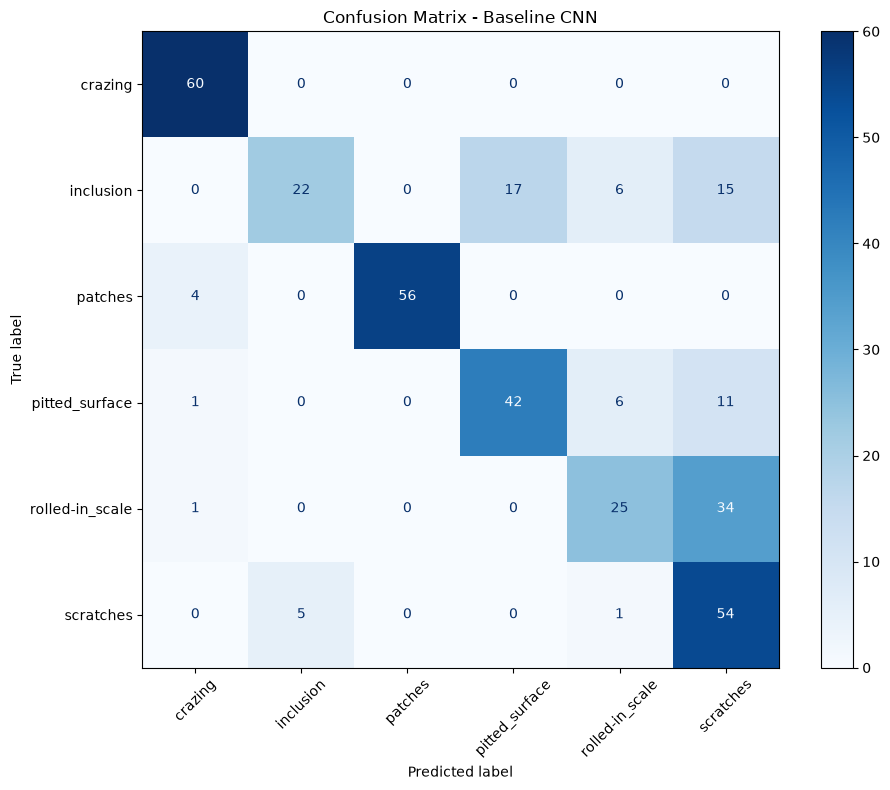

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(train_dataset.classes)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_dataset.classes
)

fig, ax = plt.subplots(figsize=(10, 8))

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("Confusion Matrix - Baseline CNN")
plt.tight_layout()
plt.show()

In [14]:
from torchvision import models
import torch.nn as nn

# Load ResNet18 with pretrained weights
weights = models.ResNet18_Weights.DEFAULT
resnet_model = models.resnet18(weights=weights)

# Replace the final classification layer
num_features = resnet_model.fc.in_features

resnet_model.fc = nn.Linear(
    num_features,
    len(train_dataset.classes)
)

print(resnet_model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\vyshn/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Linear(in_features=512, out_features=6, bias=True)


In [15]:
resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [16]:
resnet_train_dataset = ImageFolder(
    train_images_path,
    transform=resnet_transform
)

resnet_validation_dataset = ImageFolder(
    validation_images_path,
    transform=resnet_transform
)

resnet_train_loader = DataLoader(
    resnet_train_dataset,
    batch_size=32,
    shuffle=True
)

resnet_validation_loader = DataLoader(
    resnet_validation_dataset,
    batch_size=32,
    shuffle=False
)

print("Training images:", len(resnet_train_dataset))
print("Validation images:", len(resnet_validation_dataset))
print("Classes:", resnet_train_dataset.classes)


Training images: 1440
Validation images: 360
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [17]:
images, labels = next(iter(resnet_train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image minimum:", images.min().item())
print("Image maximum:", images.max().item())

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Image minimum: -2.1179039478302
Image maximum: 2.640000104904175


In [18]:
# Freeze all pretrained parameters
for param in resnet_model.parameters():
    param.requires_grad = False

# Unfreeze the final classification layer
for param in resnet_model.fc.parameters():
    param.requires_grad = True

# Count trainable parameters
trainable_params = sum(
    param.numel()
    for param in resnet_model.parameters()
    if param.requires_grad
)

print("Trainable parameters:", trainable_params)

Trainable parameters: 3078


In [19]:
resnet_criterion = nn.CrossEntropyLoss()

resnet_optimizer = torch.optim.Adam(
    resnet_model.fc.parameters(),
    lr=0.001
)

In [20]:
num_epochs = 5

for epoch in range(num_epochs):

    # Keep pretrained layers in evaluation mode
    resnet_model.eval()

    # Train the new classification layer
    resnet_model.fc.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in resnet_train_loader:

        resnet_optimizer.zero_grad()

        outputs = resnet_model(images)

        loss = resnet_criterion(outputs, labels)

        loss.backward()

        resnet_optimizer.step()

        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / len(resnet_train_loader)
    epoch_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch [1/5] Loss: 0.9333 Accuracy: 82.71%
Epoch [2/5] Loss: 0.3091 Accuracy: 98.33%
Epoch [3/5] Loss: 0.1787 Accuracy: 98.61%
Epoch [4/5] Loss: 0.1247 Accuracy: 99.24%
Epoch [5/5] Loss: 0.0950 Accuracy: 99.38%


In [21]:
resnet_model.eval()

resnet_correct = 0
resnet_total = 0

with torch.no_grad():

    for images, labels in resnet_validation_loader:

        outputs = resnet_model(images)

        predictions = outputs.argmax(dim=1)

        resnet_correct += (
            (predictions == labels).sum().item()
        )

        resnet_total += labels.size(0)

resnet_validation_accuracy = (
    100 * resnet_correct / resnet_total
)

print(
    f"ResNet18 Validation Accuracy: "
    f"{resnet_validation_accuracy:.2f}%"
)

ResNet18 Validation Accuracy: 98.61%


In [22]:
print(f"Baseline CNN: {validation_accuracy:.2f}%")
print(f"ResNet18:     {resnet_validation_accuracy:.2f}%")

Baseline CNN: 71.94%
ResNet18:     98.61%


In [23]:
from sklearn.metrics import classification_report

resnet_model.eval()

resnet_predictions = []
resnet_labels = []

with torch.no_grad():
    for images, labels in resnet_validation_loader:

        outputs = resnet_model(images)

        predictions = outputs.argmax(dim=1)

        resnet_predictions.extend(predictions.tolist())
        resnet_labels.extend(labels.tolist())

print("Total predictions:", len(resnet_predictions))
print("Total labels:", len(resnet_labels))

Total predictions: 360
Total labels: 360


In [24]:
print(classification_report(
    resnet_labels,
    resnet_predictions,
    target_names=resnet_train_dataset.classes,
    digits=4
))

                 precision    recall  f1-score   support

        crazing     1.0000    1.0000    1.0000        60
      inclusion     1.0000    0.9333    0.9655        60
        patches     1.0000    1.0000    1.0000        60
 pitted_surface     0.9524    1.0000    0.9756        60
rolled-in_scale     0.9836    1.0000    0.9917        60
      scratches     0.9833    0.9833    0.9833        60

       accuracy                         0.9861       360
      macro avg     0.9866    0.9861    0.9860       360
   weighted avg     0.9866    0.9861    0.9860       360



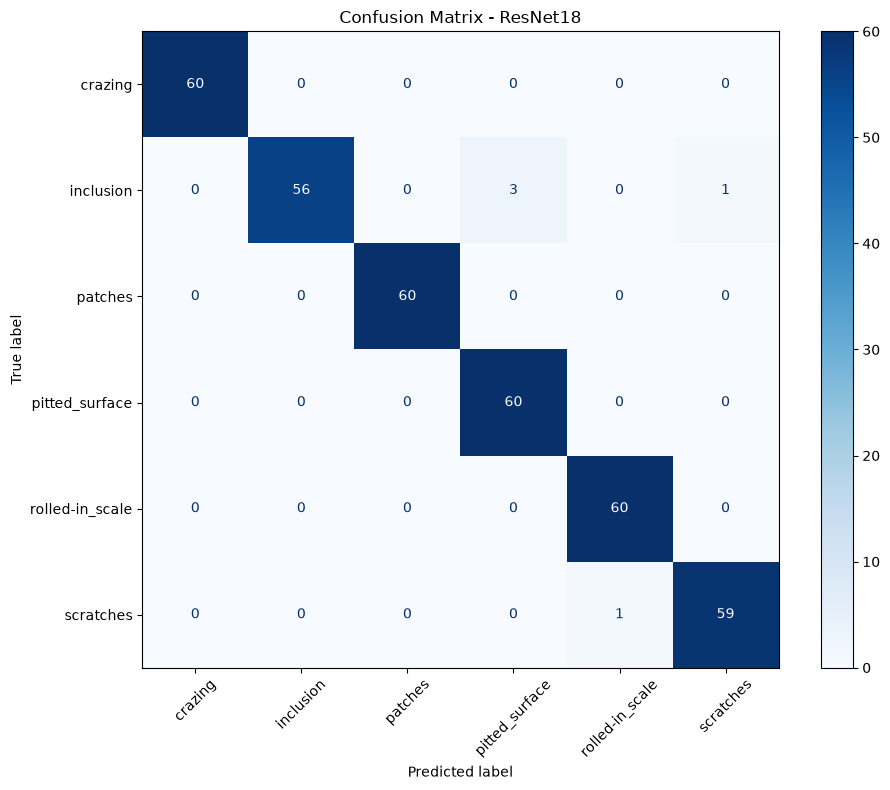

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_resnet = confusion_matrix(
    resnet_labels,
    resnet_predictions,
    labels=list(range(len(resnet_train_dataset.classes)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_resnet,
    display_labels=resnet_train_dataset.classes
)

fig, ax = plt.subplots(figsize=(10, 8))

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("Confusion Matrix - ResNet18")
plt.tight_layout()
plt.show()

In [26]:
import hashlib
from pathlib import Path


def calculate_image_hash(image_path):
    """Calculate the SHA-256 hash of an image file."""
    sha256 = hashlib.sha256()

    with open(image_path, "rb") as image_file:
        for chunk in iter(
            lambda: image_file.read(8192),
            b""
        ):
            sha256.update(chunk)

    return sha256.hexdigest()


def get_image_hashes(image_root):
    """Map each image's content hash to its file paths."""
    image_hashes = {}

    for image_path in Path(image_root).rglob("*"):
        if image_path.is_file():
            image_hash = calculate_image_hash(image_path)

            image_hashes.setdefault(
                image_hash, []
            ).append(str(image_path))

    return image_hashes


train_hashes = get_image_hashes(train_images_path)
validation_hashes = get_image_hashes(validation_images_path)

identical_hashes = set(train_hashes) & set(validation_hashes)

print("Unique training image hashes:", len(train_hashes))
print("Unique validation image hashes:", len(validation_hashes))
print("Identical image contents across splits:", len(identical_hashes))

Unique training image hashes: 1439
Unique validation image hashes: 360
Identical image contents across splits: 0


In [27]:
# Find duplicate files within the training dataset

duplicate_training_groups = {
    image_hash: paths
    for image_hash, paths in train_hashes.items()
    if len(paths) > 1
}

print("Duplicate training groups:", len(duplicate_training_groups))

for image_hash, paths in duplicate_training_groups.items():
    print("\nDuplicate files:")
    for path in paths:
        print(path)

Duplicate training groups: 1

Duplicate files:
d:\Career_Journey\Projects\Industrial_Defect_Detection\Data\Raw\NEU-DET\train\images\patches\patches_101.jpg
d:\Career_Journey\Projects\Industrial_Defect_Detection\Data\Raw\NEU-DET\train\images\patches\patches_105.jpg


In [28]:
from pathlib import Path

project_root = Path.cwd().parent

models_path = project_root / "Models"

models_path.mkdir(parents=True, exist_ok=True)

print("Models directory:", models_path)
print("Directory exists:", models_path.exists())

Models directory: d:\Career_Journey\Projects\Industrial_Defect_Detection\Models
Directory exists: True


In [29]:
import torch

model_save_path = models_path / "resnet18_neu_det.pth"

torch.save(
    resnet_model.state_dict(),
    model_save_path
)

print("Model saved to:", model_save_path)
print("File exists:", model_save_path.exists())

Model saved to: d:\Career_Journey\Projects\Industrial_Defect_Detection\Models\resnet18_neu_det.pth
File exists: True


In [30]:
from PIL import Image
from torchvision import models, transforms
import torch
import torch.nn as nn

In [31]:
# Create the ResNet18 architecture
inference_model = models.resnet18(weights=None)

# Replace the original classifier with our six-class classifier
num_features = inference_model.fc.in_features

inference_model.fc = nn.Linear(
    num_features,
    len(resnet_train_dataset.classes)
)

# Load our trained parameters
state_dict = torch.load(
    model_save_path,
    map_location="cpu",
    weights_only=True
)

inference_model.load_state_dict(state_dict)

# Set the model to evaluation mode
inference_model.eval()

print("Model loaded successfully.")

Model loaded successfully.


In [32]:
inference_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [33]:
def predict_defect(image_path):
    """
    Predict the steel surface defect shown in an image.

    Args:
        image_path: Path to the input image.

    Returns:
        Predicted defect class and confidence score.
    """

    # Open the image and ensure it has three color channels
    image = Image.open(image_path).convert("RGB")

    # Apply the same preprocessing used during training
    image_tensor = inference_transform(image)

    # Add a batch dimension
    image_tensor = image_tensor.unsqueeze(0)

    # Run inference without calculating gradients
    with torch.no_grad():
        outputs = inference_model(image_tensor)

        # Convert output scores into probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Find the class with the highest probability
        confidence, predicted_index = probabilities.max(dim=1)

    # Convert the predicted index into its class name
    predicted_class = resnet_train_dataset.classes[
        predicted_index.item()
    ]

    confidence_score = confidence.item() * 100

    return {
        "predicted_class": predicted_class,
        "confidence": round(confidence_score, 2)
    }

In [34]:
test_image_path = os.path.join(
    validation_images_path,
    "patches",
    os.listdir(
        os.path.join(validation_images_path, "patches")
    )[0]
)

result = predict_defect(test_image_path)

print("Image:", test_image_path)
print("Predicted defect:", result["predicted_class"])
print("Confidence:", f'{result["confidence"]}%')

Image: d:\Career_Journey\Projects\Industrial_Defect_Detection\Data\Raw\NEU-DET\validation\images\patches\patches_241.jpg
Predicted defect: patches
Confidence: 95.23%


In [35]:
import json

class_mapping = {
    index: class_name
    for index, class_name in enumerate(
        resnet_train_dataset.classes
    )
}

mapping_path = models_path / "class_mapping.json"

with open(mapping_path, "w") as file:
    json.dump(class_mapping, file, indent=4)

print("Class mapping saved to:", mapping_path)
print(class_mapping)

Class mapping saved to: d:\Career_Journey\Projects\Industrial_Defect_Detection\Models\class_mapping.json
{0: 'crazing', 1: 'inclusion', 2: 'patches', 3: 'pitted_surface', 4: 'rolled-in_scale', 5: 'scratches'}


In [39]:
import os
from pathlib import Path

project_root = Path.cwd().parent

print("Current directory:", Path.cwd())
print("Project root:", project_root)
print("Models folder exists:", (project_root / "Models").is_dir())

Current directory: d:\Career_Journey\Projects\Industrial_Defect_Detection\Notebooks
Project root: d:\Career_Journey\Projects\Industrial_Defect_Detection
Models folder exists: True


In [40]:
import sys

project_root = project_root.resolve()

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root added:", str(project_root) in sys.path)

Project root added: True


In [41]:
from Models.predict import predict_defect

print("Prediction module imported successfully.")

Prediction module imported successfully.


In [42]:
test_image_path = (
    project_root
    / "Data"
    / "Raw"
    / "NEU-DET"
    / "validation"
    / "images"
    / "patches"
    / "patches_241.jpg"
)

result = predict_defect(test_image_path)

print("Predicted defect:", result["predicted_class"])
print("Confidence:", f'{result["confidence"]}%')

Predicted defect: patches
Confidence: 95.23%


In [44]:
external_image_path = (
    project_root
    / "Data"
    / "External_test"
    / "scratches_241.jpg"
)

print("Image exists:", external_image_path.is_file())

result = predict_defect(external_image_path)

print("Actual defect: scratches")
print("Predicted defect:", result["predicted_class"])
print("Confidence:", f'{result["confidence"]}%')

Image exists: True
Actual defect: scratches
Predicted defect: scratches
Confidence: 99.23%
